# code_118 · Typed relations and time-bounded link evidence

**Book:** section 23.4. A self-contained architecture laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_23_GUIDE.md), [run evidence](../CHAPTER_23_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_118).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2518;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2518


<a id="typed-history-contract"></a>
 ## Relation meaning and availability precede aggregation
 Generate sixty buildings, each with four members, four sensors and three inspection entities. Building/member/sensor/inspection features have different meanings and dimensions. At decision day ten, a sensor reading with event day nine but receipt day eleven is unavailable; two inspection assignments/reports are historical, while a third created inspection has only its known priority and no future outcome/edge. Train a relation-specific graph update to predict later member damage on 40/10/10 whole buildings. Compare a non-neural typed-aggregate logistic baseline. A separate feature-based typed link decoder fits historical inspection-to-member assignments and predicts added links during days ten to twelve on final buildings. All eligible same-building typed pairs are enumerated; historical positives are excluded from the future candidate set. Current nonedges are not declared permanent negatives, and future positives are never used to filter training negatives.


,model,development_Brier,final_Brier
0,Typed aggregate logistic,0.214449,0.189573
1,Relation-specific graph,0.236634,0.216907


{'development_historical_Brier': 0.13947323629838693, 'best_step': 300, 'future_final_Brier': 0.16745538352977443, 'future_final_AP': 0.5677204133177026, 'future_final_MRR': 0.9166666666666666, 'future_candidate_pairs': 70, 'future_positive_pairs': 20, 'future_positive_pairs_retained_as_training_historical_nonedge': 40}


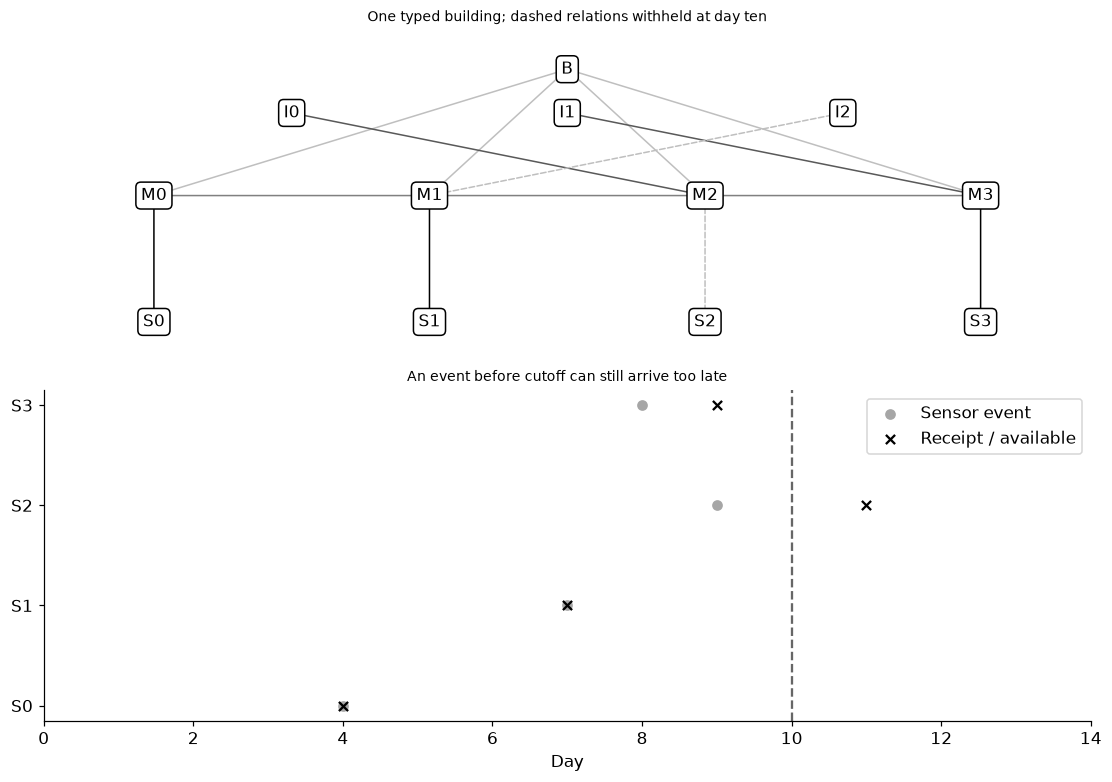

In [2]:
import copy
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
B,M,I=60,4,3;cutoff=10;building=rng.normal(size=(B,1,2));member=rng.normal(size=(B,M,3));reading=rng.normal(size=(B,M));quality=rng.uniform(.5,1,(B,M));priority=rng.normal(size=(B,I));rating=rng.normal(size=(B,I));event=np.array([4,7,9,8]);receipt=np.array([4,7,11,9]);sensor_valid=(event<=cutoff)&(receipt<=cutoff);inspection_created=np.array([1,6,9]);assignment_day=np.array([3,8,12]);report_receipt=np.array([5,9,13]);report_valid=report_receipt<=cutoff
assignment=np.argmin(np.abs(priority[:,:,None]-member[:,None,:,0]),axis=2);future_second=np.argsort(np.abs(priority[:,0,None]-member[:,:,0]),axis=1)[:,1];relations=np.zeros((B,M,I))
for b in range(B):
    for j in range(I):
        if assignment_day[j]<=cutoff:relations[b,assignment[b,j],j]=1
connected=np.zeros((M,M))
for i in range(M-1):connected[i,i+1]=connected[i+1,i]=1
neighbor=connected/connected.sum(1,keepdims=True);historical_rating=np.einsum('bmi,bi->bm',relations,rating*report_valid)/np.maximum(relations.sum(-1),1);node_logit=.8*member[:,:,0]+1.2*reading*sensor_valid+.4*building[:,0,1,None]+.3*historical_rating;node_probability=1/(1+np.exp(-node_logit));target=rng.binomial(1,node_probability).astype(float)
sensor=np.stack([reading*sensor_valid,quality,np.broadcast_to(sensor_valid,(B,M))],axis=-1);inspection=np.stack([rating*report_valid,priority,np.broadcast_to(report_valid,(B,I))],axis=-1);raw={'building':building,'member':member,'sensor':sensor,'inspection':inspection};features={};scalers={}
for kind,values in raw.items():
    scaler=StandardScaler().fit(values[:40].reshape(-1,values.shape[-1]));features[kind]=torch.tensor(scaler.transform(values.reshape(-1,values.shape[-1])).reshape(values.shape));scalers[kind]=scaler
relation=torch.tensor(relations);p=torch.tensor(neighbor);sensor_mask=torch.tensor(sensor_valid.astype(float));y=torch.tensor(target)
class TypedGraph(nn.Module):
    def __init__(self):
        super().__init__();self.encoders=nn.ModuleDict({kind:nn.Linear(values.shape[-1],8) for kind,values in features.items()});self.own=nn.Linear(8,8);self.by_relation=nn.ModuleDict({kind:nn.Linear(8,8,bias=False) for kind in ['has_member','measures','records','connected']});self.head=nn.Linear(8,1)
    def forward(self,inputs):
        h={kind:torch.tanh(self.encoders[kind](value)) for kind,value in inputs.items()};inspection_mean=relation@h['inspection']/relation.sum(-1,keepdim=True).clamp_min(1);out=self.own(h['member'])+self.by_relation['has_member'](h['building']).expand(-1,M,-1)+self.by_relation['measures'](h['sensor'])*sensor_mask[None,:,None]+self.by_relation['records'](inspection_mean)+self.by_relation['connected'](p@h['member']);return self.head(torch.relu(out)).squeeze(-1)
aggregate=np.concatenate([member,reading[:,:,None]*sensor_valid[None,:,None],np.broadcast_to(building,(B,M,2)),historical_rating[:,:,None],neighbor@member],axis=-1);baseline=LogisticRegression(C=1,max_iter=1000).fit(aggregate[:40].reshape(-1,aggregate.shape[-1]),target[:40].ravel());baseline_probability=baseline.predict_proba(aggregate.reshape(-1,aggregate.shape[-1]))[:,1].reshape(B,M);candidates=[]
for rate in [.005,.01]:
    torch.manual_seed(SEED);model=TypedGraph();opt=torch.optim.AdamW(model.parameters(),lr=rate,weight_decay=.001);best=np.inf
    for step in range(1,301):
        opt.zero_grad();pred=model(features);loss=nn.functional.binary_cross_entropy_with_logits(pred[:40],y[:40]);loss.backward();opt.step()
        if step%10==0:
            with torch.no_grad():score=float(torch.mean((model(features)[40:50].sigmoid()-y[40:50])**2))
            if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
    candidates.append({'rate':rate,'development_Brier':best,'best_step':best_step,'state':state})
selected=min(candidates,key=lambda r:r['development_Brier']);model.load_state_dict(selected['state']);model.eval()
with torch.no_grad():node_prediction=model(features).sigmoid().numpy()
node_rows=[{'model':name,'development_Brier':float(np.mean((prediction[40:50]-target[40:50])**2)),'final_Brier':float(np.mean((prediction[50:]-target[50:])**2))} for name,prediction in [('Typed aggregate logistic',baseline_probability),('Relation-specific graph',node_prediction)]]
# A supplied future damage report is a forbidden perfect surrogate, not an admitted model.
future_report=target.copy();assert np.mean((future_report[50:]-target[50:])**2)==0
changed_reading=reading.copy();changed_reading[:,~sensor_valid]+=1000;np.testing.assert_array_equal(changed_reading*sensor_valid,reading*sensor_valid)
assert inspection_created.max()<=cutoff and np.all(assignment_day[:2]<=cutoff) and assignment_day[2]>cutoff and not sensor_valid[2]
# Inductive typed pair decoder: member load and inspection priority are known before assignment.
historical=[];future=[];future_positive_in_train_negative=0
for b in range(B):
    for j in [0,1]:
        for m in range(M):
            historical.append((b,j,m,float(m==assignment[b,j])))
            if b<40 and j==0 and m==future_second[b] and m!=assignment[b,j]:future_positive_in_train_negative+=1
    for j in [0,2]:
        for m in range(M):
            if j==0 and m==assignment[b,0]:continue
            future.append((b,j,m,float(m==(future_second[b] if j==0 else assignment[b,2]))))
def pair_tensors(records):
    b,j,m,label=np.array(records).T;b=b.astype(int);j=j.astype(int);m=m.astype(int);return b,j,torch.tensor(member[b,m,0,None]),torch.tensor(priority[b,j,None]),torch.tensor(label)
hb,hj,hm,hi,hy=pair_tensors(historical);fb,fj,fm,fi,fy=pair_tensors(future)
class TypedLink(nn.Module):
    def __init__(self):super().__init__();self.member=nn.Linear(1,4,bias=False);self.inspection=nn.Linear(1,4,bias=False);self.log_scale=nn.Parameter(torch.tensor(0.));self.bias=nn.Parameter(torch.tensor(0.))
    def forward(self,m,i):return self.bias-self.log_scale.exp()*torch.sum((self.member(m)-self.inspection(i))**2,dim=-1)
torch.manual_seed(SEED+1);link=TypedLink();optimizer=torch.optim.Adam(link.parameters(),lr=.02);best=np.inf
for step in range(1,501):
    optimizer.zero_grad();loss=nn.functional.binary_cross_entropy_with_logits(link(hm[hb<40],hi[hb<40]),hy[hb<40]);loss.backward();optimizer.step()
    if step%10==0:
        with torch.no_grad():score=float(torch.mean((link(hm[(hb>=40)&(hb<50)],hi[(hb>=40)&(hb<50)]).sigmoid()-hy[(hb>=40)&(hb<50)])**2))
        if score<best:best=score;link_state=copy.deepcopy(link.state_dict());link_step=step
link.load_state_dict(link_state)
with torch.no_grad():future_probability=link(fm,fi).sigmoid().numpy()
ranks=[]
for b in range(50,60):
    for j in [0,2]:
        chosen=(fb==b)&(fj==j);scores=future_probability[chosen];labels=fy.numpy()[chosen];order=np.argsort(-scores,kind='stable');ranks.append(int(np.flatnonzero(labels[order]==1)[0]+1))
final_pairs=fb>=50;assert int(fy[final_pairs].sum())==20 and final_pairs.sum()==70 and future_positive_in_train_negative==40
link_result={'development_historical_Brier':best,'best_step':link_step,'future_final_Brier':float(np.mean((future_probability[final_pairs]-fy.numpy()[final_pairs])**2)),'future_final_AP':float(average_precision_score(fy.numpy()[final_pairs],future_probability[final_pairs])),'future_final_MRR':float(np.mean(1/np.array(ranks))),'future_candidate_pairs':int(final_pairs.sum()),'future_positive_pairs':int(fy[final_pairs].sum()),'future_positive_pairs_retained_as_training_historical_nonedge':future_positive_in_train_negative}
RESULTS.update(node_comparisons=node_rows,node_candidates=[{k:v for k,v in r.items() if k!='state'} for r in candidates],selected_node_rate=selected['rate'],selected_node_step=selected['best_step'],typed_graph_parameters=sum(t.numel() for t in model.parameters()),link_parameters=sum(t.numel() for t in link.parameters()),link_assessment=link_result,split_buildings=[40,10,10],decision_day=cutoff,sensor_event_days=event.tolist(),sensor_receipt_days=receipt.tolist(),sensor_admitted=sensor_valid.tolist(),inspection_creation_days=inspection_created.tolist(),inspection_assignment_days=assignment_day.tolist(),inspection_report_receipt_days=report_receipt.tolist(),historical_assignment_edges=int(relations.sum()),forbidden_future_report_Brier=0.,unavailable_reading_perturbation_changes_admitted_values=False);display(pd.DataFrame(node_rows));print(link_result)
fig,axes=plt.subplots(2,1,figsize=(10,7));ax=axes[0];pos={'B':(1.5,3)}
for m in range(M):pos[f'M{m}']=(m,1.7);pos[f'S{m}']=(m,.4)
for j in range(I):pos[f'I{j}']=(j+.5,2.55)
for m in range(M):
    ax.annotate('',xy=pos[f'M{m}'],xytext=pos['B'],arrowprops={'arrowstyle':'->','color':'.75'})
    ax.annotate('',xy=pos[f'M{m}'],xytext=pos[f'S{m}'],arrowprops={'arrowstyle':'->','color':'black' if sensor_valid[m] else '.75','linestyle':'-' if sensor_valid[m] else '--'})
for m in range(M-1):ax.annotate('',xy=pos[f'M{m+1}'],xytext=pos[f'M{m}'],arrowprops={'arrowstyle':'<->','color':'.5'})
for j in range(I):ax.annotate('',xy=pos[f'M{assignment[50,j]}'],xytext=pos[f'I{j}'],arrowprops={'arrowstyle':'->','color':'.35' if j<2 else '.75','linestyle':'-' if j<2 else '--'})
for label,(px,py) in pos.items():ax.text(px,py,label,ha='center',va='center',bbox={'boxstyle':'round','facecolor':'white','edgecolor':'black'})
ax.set(xlim=(-.4,3.4),ylim=(0,3.4),title='One typed building; dashed relations withheld at day ten');ax.axis('off')
axes[1].scatter(event,np.arange(4),marker='o',color='.65',label='Sensor event');axes[1].scatter(receipt,np.arange(4),marker='x',color='black',label='Receipt / available');axes[1].axvline(cutoff,color='.4',linestyle='--');axes[1].set(xlim=(0,14),yticks=np.arange(4),yticklabels=['S0','S1','S2','S3'],xlabel='Day',title='An event before cutoff can still arrive too late');axes[1].legend();plt.show()


<a id="typed-negative-limits"></a>
 ## Current absence is a time-indexed claim
 Relation-specific functions keep building/member/sensor/inspection semantics distinct. Edge direction is declared; reverse relations and self loops are not silently manufactured. A sensor event before the cutoff is excluded when its receipt is later. A future inspection entity may already exist, yet its later assignment and report remain unavailable. Historical nonedge candidates include forty pairs that become positive later: their future status is deliberately not used to curate training. Future added-edge assessment excludes already historical positives and retains seventy eligible pairs with twenty additions on ten held-out buildings. It evaluates this constructed observed candidate universe, not all never-observed links or a permanent absence truth. The direct future-report surrogate demonstrates forbidden leakage and is excluded from admitted comparisons. Typed feature encoders support unseen building entities; no learned identity lookup is used.


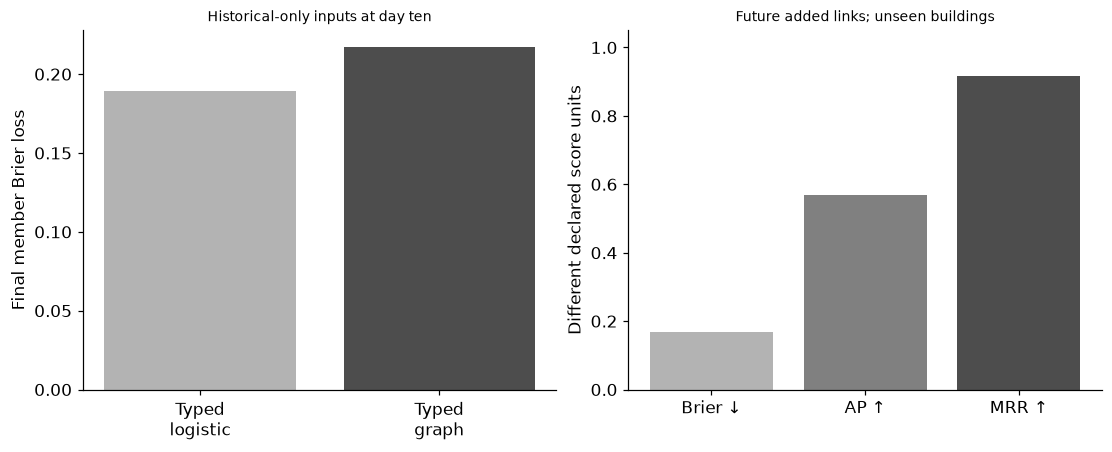

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(2),[r['final_Brier'] for r in node_rows],color=['.7','.3']);axes[0].set(xticks=range(2),xticklabels=['Typed\nlogistic','Typed\ngraph'],ylabel='Final member Brier loss',title='Historical-only inputs at day ten')
axes[1].bar(range(3),[link_result['future_final_Brier'],link_result['future_final_AP'],link_result['future_final_MRR']],color=['.7','.5','.3']);axes[1].set(xticks=range(3),xticklabels=['Brier ↓','AP ↑','MRR ↑'],ylim=(0,1.05),ylabel='Different declared score units',title='Future added links; unseen buildings');plt.show()
assert np.isfinite(future_probability).all() and all(0<=r['final_Brier']<=1 for r in node_rows)


In [4]:
summary={'example_id':'code_118','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual relation-specific graph update', 'node and edge availability clocks', 'historical-only typed snapshot', 'trained typed link decoder', 'future-positive negative audit'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual relation-specific graph update", "node and edge availability clocks", "historical-only typed snapshot", "trained typed link decoder", "future-positive negative audit"], "elapsed_seconds": 1.336, "example_id": "code_118", "hardware": "Darwin arm64 CPU", "results": {"decision_day": 10, "forbidden_future_report_Brier": 0.0, "historical_assignment_edges": 120, "inspection_assignment_days": [3, 8, 12], "inspection_creation_days": [1, 6, 9], "inspection_report_receipt_days": [5, 9, 13], "link_assessment": {"best_step": 300, "development_historical_Brier": 0.13947323629838693, "future_candidate_pairs": 70, "future_final_AP": 0.5677204133177026, "future_final_Brier": 0.16745538352977443, "future_final_MRR": 0.9166666666666666, "future_positive_pairs": 20, "future_positive_pairs_retained_as_training_historical_nonedge": 40}, "link_parameters": 10, "node_candidates": [{"best_step": 50, "development_Brier": 0.23663388777510425, "rate": 0.0